In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/tmp/ipykernel_439244/4052065354.py:88: MatplotlibDeprecationWarning: The label function was deprecated in Matplotlib 3.1 and will be removed in 3.8. Use Tick.label1 instead.
  tick.label.set_fontsize(10)


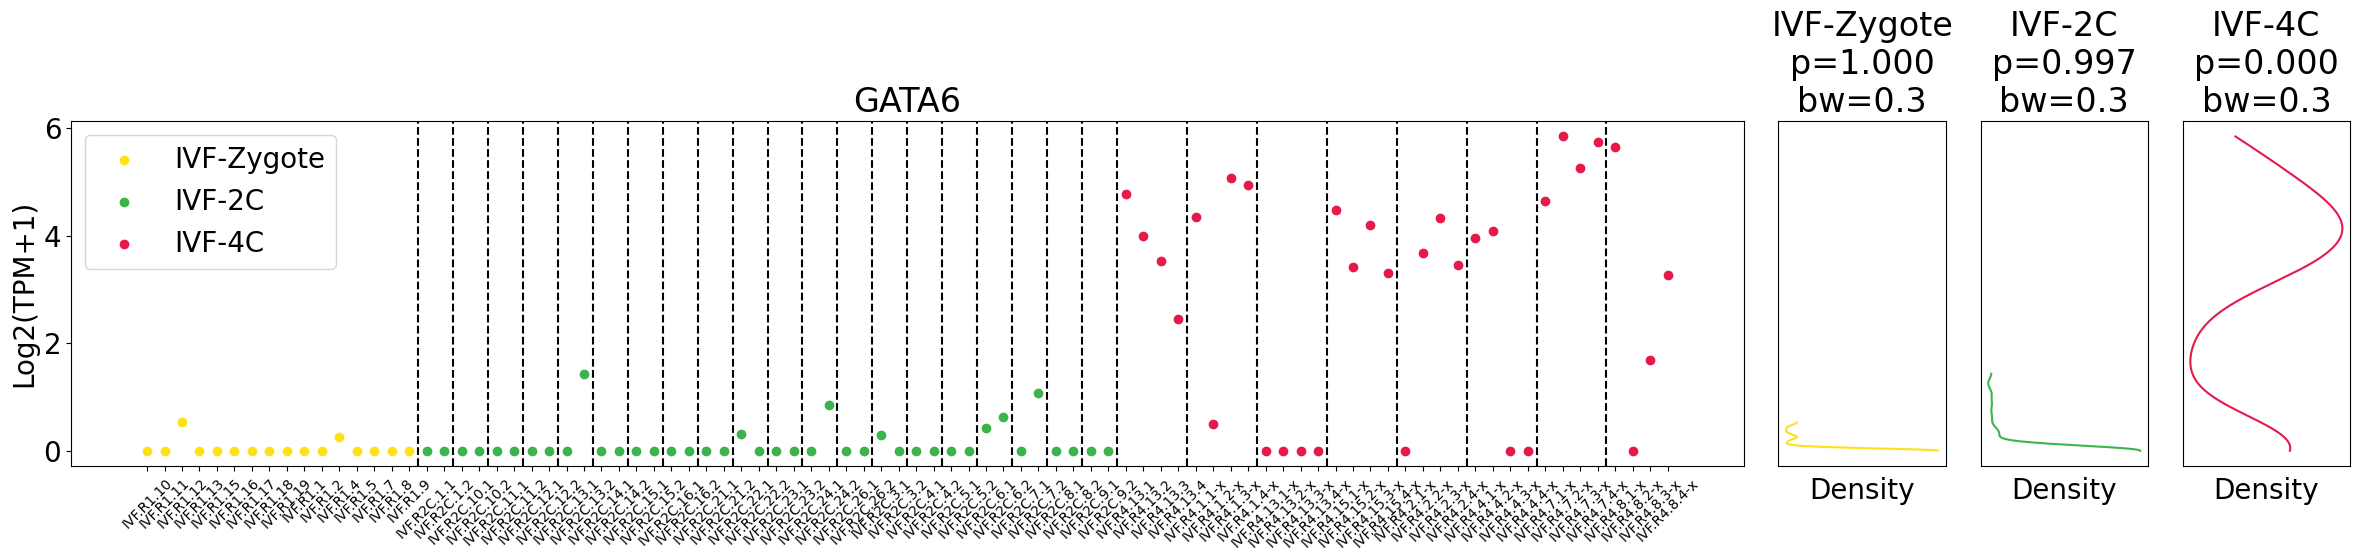

In [2]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import diptest
from scipy.stats import gaussian_kde
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置全局字体大小
plt.rcParams.update({'font.size': 20})

# 读取表达矩阵文件
with open('IVF_full_log2TPM_genename.txt', 'r') as file:
    lines = file.readlines()

# 获取细胞名
cell_names = lines[0].strip().split('\t')[1:]

# 存储基因表达数据
gene_data = {}
for line in lines[1:]:
    parts = line.strip().split('\t')
    gene_id = parts[0]
    expression_data = list(map(float, parts[1:]))
    gene_data[gene_id] = expression_data

# 选择目标基因
gene_id = "GATA6"
expression_data = gene_data[gene_id]

# 提取各阶段索引和数据
mii_indices = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R1')]
c2_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R2C')]
c4_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R4')]

mii_expression = np.array([expression_data[i] for i in mii_indices])
c2_expression  = np.array([expression_data[i] for i in c2_indices])
c4_expression  = np.array([expression_data[i] for i in c4_indices])

# 创建图形和子图
fig = plt.figure(figsize=(24, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[10, 1, 1, 1])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])
ax4 = plt.subplot(gs[3])

# 散点图
ax1.scatter([cell_names[i] for i in mii_indices], mii_expression, color='#ffe119', label='IVF-Zygote')
ax1.scatter([cell_names[i] for i in c2_indices], c2_expression, color='#3cb44b', label='IVF-2C')
ax1.scatter([cell_names[i] for i in c4_indices], c4_expression, color='#e6194b', label='IVF-4C')
ax1.set_title(gene_id)
ax1.set_ylabel('Log2(TPM+1)')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

# 添加虚线
for x in [15.5,17.5,19.5,21.5,23.5,25.5,27.5,29.5,31.5,33.5,35.5,
          37.5,39.5,41.5,43.5,45.5,47.5,49.5,51.5,53.5,55.5,
          59.5,63.5,67.5,71.5,75.5,79.5,83.5]:
    ax1.axvline(x=x, color='black', linestyle='--')

# 密度图函数
def plot_density(ax, data, color, label, bw=0.3):
    kde = gaussian_kde(data, bw_method=bw)
    y_vals = np.linspace(min(data), max(data), 500)
    x_vals = kde(y_vals)
    ax.plot(x_vals, y_vals, color=color)
    ax.set_ylim(ax1.get_ylim())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Density')
    ax.grid(True)
    p = diptest.diptest(data)[1]
    ax.set_title(f'{label}\np={p:.3f}\nbw={bw}')


# 绘制密度图
plot_density(ax2, mii_expression, '#ffe119', 'IVF-Zygote', bw=0.3)
plot_density(ax3, c2_expression,  '#3cb44b', 'IVF-2C',      bw=0.3)
plot_density(ax4, c4_expression,  '#e6194b', 'IVF-4C',      bw=0.3)

# 调整字体
for tick in ax1.xaxis.get_major_ticks():
    tick.label.set_fontsize(10)

plt.tight_layout()
# 保存图像为 PDF
plt.savefig('IVF_GATA6_expression.svg', dpi=300, bbox_inches='tight', transparent=True)


/home/lihaoxing/tmp/ipykernel_439244/626456118.py:88: MatplotlibDeprecationWarning: The label function was deprecated in Matplotlib 3.1 and will be removed in 3.8. Use Tick.label1 instead.
  tick.label.set_fontsize(10)


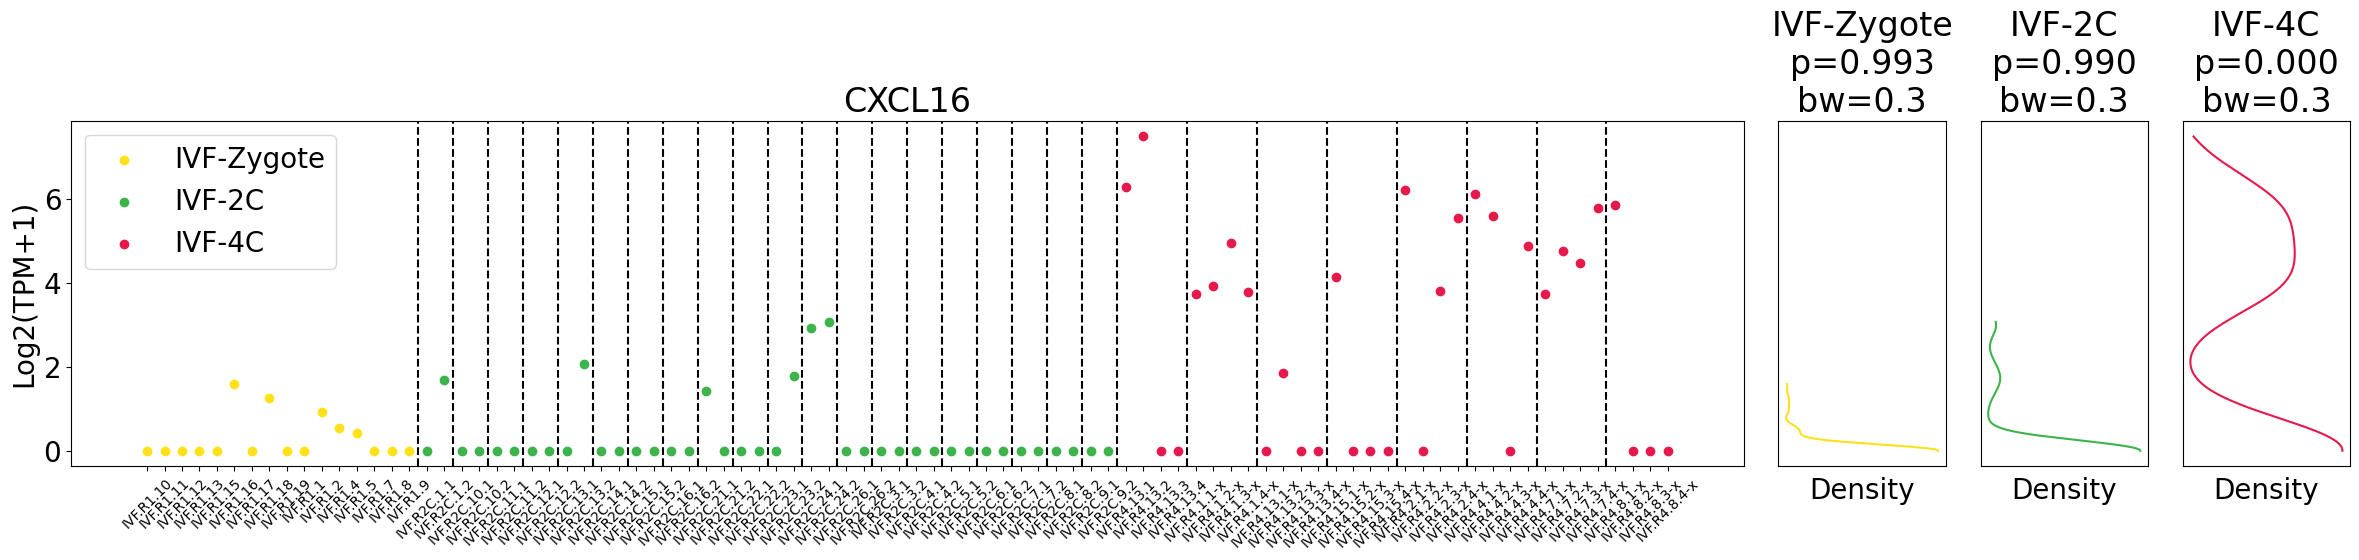

In [3]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import diptest
from scipy.stats import gaussian_kde
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置全局字体大小
plt.rcParams.update({'font.size': 20})

# 读取表达矩阵文件
with open('IVF_full_log2TPM_genename.txt', 'r') as file:
    lines = file.readlines()

# 获取细胞名
cell_names = lines[0].strip().split('\t')[1:]

# 存储基因表达数据
gene_data = {}
for line in lines[1:]:
    parts = line.strip().split('\t')
    gene_id = parts[0]
    expression_data = list(map(float, parts[1:]))
    gene_data[gene_id] = expression_data

# 选择目标基因
gene_id = "CXCL16"
expression_data = gene_data[gene_id]

# 提取各阶段索引和数据
mii_indices = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R1')]
c2_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R2C')]
c4_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R4')]

mii_expression = np.array([expression_data[i] for i in mii_indices])
c2_expression  = np.array([expression_data[i] for i in c2_indices])
c4_expression  = np.array([expression_data[i] for i in c4_indices])

# 创建图形和子图
fig = plt.figure(figsize=(24, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[10, 1, 1, 1])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])
ax4 = plt.subplot(gs[3])

# 散点图
ax1.scatter([cell_names[i] for i in mii_indices], mii_expression, color='#ffe119', label='IVF-Zygote')
ax1.scatter([cell_names[i] for i in c2_indices], c2_expression, color='#3cb44b', label='IVF-2C')
ax1.scatter([cell_names[i] for i in c4_indices], c4_expression, color='#e6194b', label='IVF-4C')
ax1.set_title(gene_id)
ax1.set_ylabel('Log2(TPM+1)')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

# 添加虚线
for x in [15.5,17.5,19.5,21.5,23.5,25.5,27.5,29.5,31.5,33.5,35.5,
          37.5,39.5,41.5,43.5,45.5,47.5,49.5,51.5,53.5,55.5,
          59.5,63.5,67.5,71.5,75.5,79.5,83.5]:
    ax1.axvline(x=x, color='black', linestyle='--')

# 密度图函数
def plot_density(ax, data, color, label, bw=0.2):
    kde = gaussian_kde(data, bw_method=bw)
    y_vals = np.linspace(min(data), max(data), 500)
    x_vals = kde(y_vals)
    ax.plot(x_vals, y_vals, color=color)
    ax.set_ylim(ax1.get_ylim())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Density')
    ax.grid(True)
    p = diptest.diptest(data)[1]
    ax.set_title(f'{label}\np={p:.3f}\nbw={bw}')


# 绘制密度图
plot_density(ax2, mii_expression, '#ffe119', 'IVF-Zygote', bw=0.3)
plot_density(ax3, c2_expression,  '#3cb44b', 'IVF-2C',      bw=0.3)
plot_density(ax4, c4_expression,  '#e6194b', 'IVF-4C',      bw=0.3)

# 调整字体
for tick in ax1.xaxis.get_major_ticks():
    tick.label.set_fontsize(10)

plt.tight_layout()
# 保存图像为 PDF
plt.savefig('IVF_CXCL16_expression.svg', dpi=300, bbox_inches='tight', transparent=True)


/home/lihaoxing/tmp/ipykernel_439244/1885427496.py:88: MatplotlibDeprecationWarning: The label function was deprecated in Matplotlib 3.1 and will be removed in 3.8. Use Tick.label1 instead.
  tick.label.set_fontsize(10)


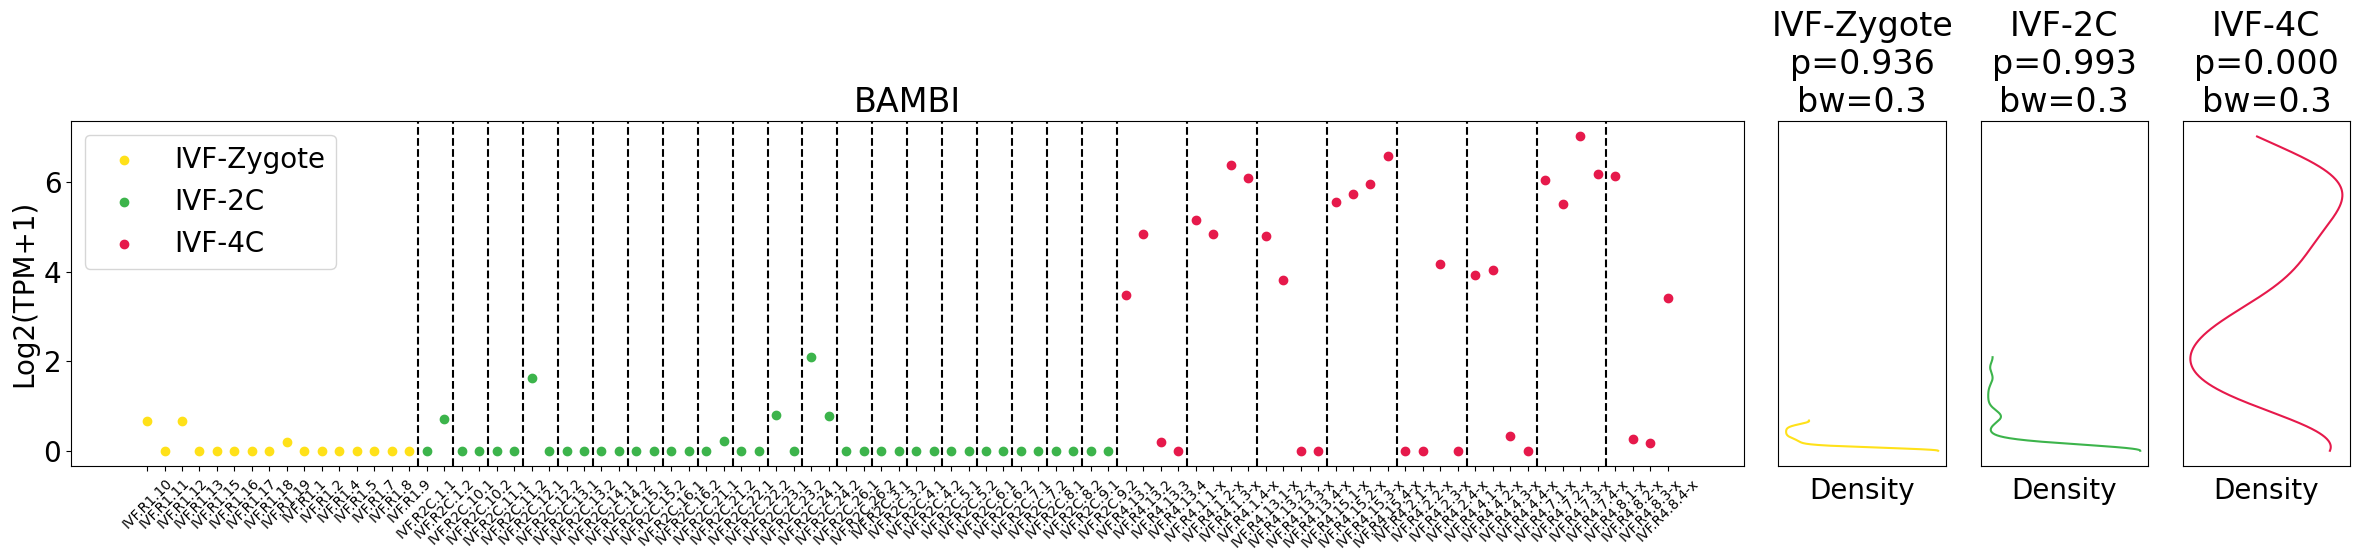

In [4]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import diptest
from scipy.stats import gaussian_kde
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置全局字体大小
plt.rcParams.update({'font.size': 20})

# 读取表达矩阵文件
with open('IVF_full_log2TPM_genename.txt', 'r') as file:
    lines = file.readlines()

# 获取细胞名
cell_names = lines[0].strip().split('\t')[1:]

# 存储基因表达数据
gene_data = {}
for line in lines[1:]:
    parts = line.strip().split('\t')
    gene_id = parts[0]
    expression_data = list(map(float, parts[1:]))
    gene_data[gene_id] = expression_data

# 选择目标基因
gene_id = "BAMBI"
expression_data = gene_data[gene_id]

# 提取各阶段索引和数据
mii_indices = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R1')]
c2_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R2C')]
c4_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R4')]

mii_expression = np.array([expression_data[i] for i in mii_indices])
c2_expression  = np.array([expression_data[i] for i in c2_indices])
c4_expression  = np.array([expression_data[i] for i in c4_indices])

# 创建图形和子图
fig = plt.figure(figsize=(24, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[10, 1, 1, 1])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])
ax4 = plt.subplot(gs[3])

# 散点图
ax1.scatter([cell_names[i] for i in mii_indices], mii_expression, color='#ffe119', label='IVF-Zygote')
ax1.scatter([cell_names[i] for i in c2_indices], c2_expression, color='#3cb44b', label='IVF-2C')
ax1.scatter([cell_names[i] for i in c4_indices], c4_expression, color='#e6194b', label='IVF-4C')
ax1.set_title(gene_id)
ax1.set_ylabel('Log2(TPM+1)')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

# 添加虚线
for x in [15.5,17.5,19.5,21.5,23.5,25.5,27.5,29.5,31.5,33.5,35.5,
          37.5,39.5,41.5,43.5,45.5,47.5,49.5,51.5,53.5,55.5,
          59.5,63.5,67.5,71.5,75.5,79.5,83.5]:
    ax1.axvline(x=x, color='black', linestyle='--')

# 密度图函数
def plot_density(ax, data, color, label, bw=0.2):
    kde = gaussian_kde(data, bw_method=bw)
    y_vals = np.linspace(min(data), max(data), 500)
    x_vals = kde(y_vals)
    ax.plot(x_vals, y_vals, color=color)
    ax.set_ylim(ax1.get_ylim())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Density')
    ax.grid(True)
    p = diptest.diptest(data)[1]
    ax.set_title(f'{label}\np={p:.3f}\nbw={bw}')


# 绘制密度图
plot_density(ax2, mii_expression, '#ffe119', 'IVF-Zygote', bw=0.3)
plot_density(ax3, c2_expression,  '#3cb44b', 'IVF-2C',     bw=0.3)
plot_density(ax4, c4_expression,  '#e6194b', 'IVF-4C',     bw=0.3)

# 调整字体
for tick in ax1.xaxis.get_major_ticks():
    tick.label.set_fontsize(10)

plt.tight_layout()
# 保存图像为 PDF
plt.savefig('IVF_BAMBI_expression.svg', dpi=300, bbox_inches='tight', transparent=True)


/home/lihaoxing/tmp/ipykernel_439244/2379453698.py:88: MatplotlibDeprecationWarning: The label function was deprecated in Matplotlib 3.1 and will be removed in 3.8. Use Tick.label1 instead.
  tick.label.set_fontsize(10)


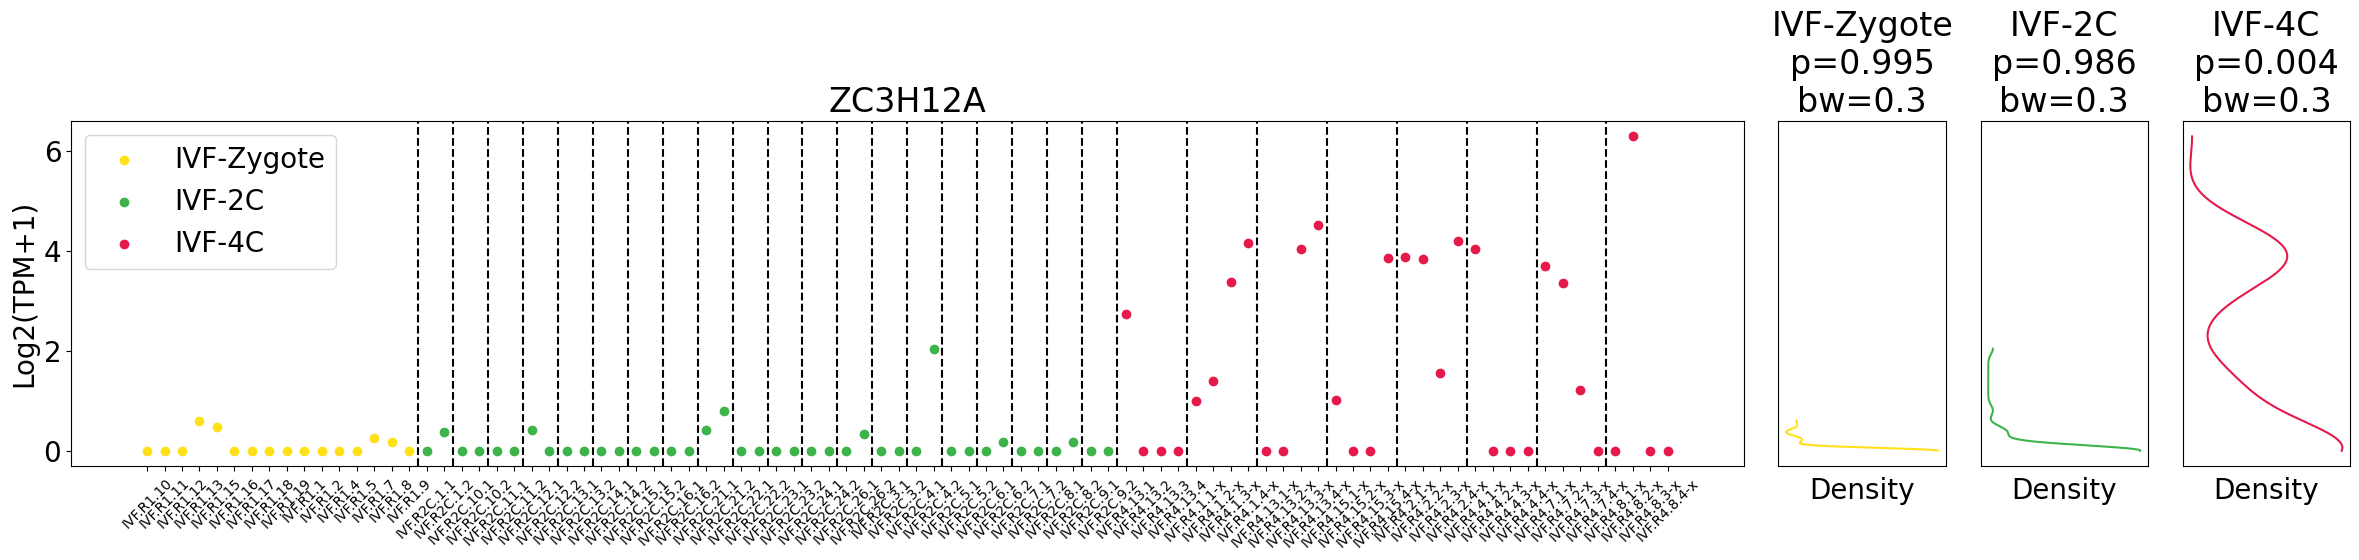

In [5]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import diptest
from scipy.stats import gaussian_kde
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置全局字体大小
plt.rcParams.update({'font.size': 20})

# 读取表达矩阵文件
with open('IVF_full_log2TPM_genename.txt', 'r') as file:
    lines = file.readlines()

# 获取细胞名
cell_names = lines[0].strip().split('\t')[1:]

# 存储基因表达数据
gene_data = {}
for line in lines[1:]:
    parts = line.strip().split('\t')
    gene_id = parts[0]
    expression_data = list(map(float, parts[1:]))
    gene_data[gene_id] = expression_data

# 选择目标基因
gene_id = "ZC3H12A"
expression_data = gene_data[gene_id]

# 提取各阶段索引和数据
mii_indices = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R1')]
c2_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R2C')]
c4_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R4')]

mii_expression = np.array([expression_data[i] for i in mii_indices])
c2_expression  = np.array([expression_data[i] for i in c2_indices])
c4_expression  = np.array([expression_data[i] for i in c4_indices])

# 创建图形和子图
fig = plt.figure(figsize=(24, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[10, 1, 1, 1])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])
ax4 = plt.subplot(gs[3])

# 散点图
ax1.scatter([cell_names[i] for i in mii_indices], mii_expression, color='#ffe119', label='IVF-Zygote')
ax1.scatter([cell_names[i] for i in c2_indices], c2_expression, color='#3cb44b', label='IVF-2C')
ax1.scatter([cell_names[i] for i in c4_indices], c4_expression, color='#e6194b', label='IVF-4C')
ax1.set_title(gene_id)
ax1.set_ylabel('Log2(TPM+1)')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

# 添加虚线
for x in [15.5,17.5,19.5,21.5,23.5,25.5,27.5,29.5,31.5,33.5,35.5,
          37.5,39.5,41.5,43.5,45.5,47.5,49.5,51.5,53.5,55.5,
          59.5,63.5,67.5,71.5,75.5,79.5,83.5]:
    ax1.axvline(x=x, color='black', linestyle='--')

# 密度图函数
def plot_density(ax, data, color, label, bw=0.2):
    kde = gaussian_kde(data, bw_method=bw)
    y_vals = np.linspace(min(data), max(data), 500)
    x_vals = kde(y_vals)
    ax.plot(x_vals, y_vals, color=color)
    ax.set_ylim(ax1.get_ylim())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Density')
    ax.grid(True)
    p = diptest.diptest(data)[1]
    ax.set_title(f'{label}\np={p:.3f}\nbw={bw}')


# 绘制密度图
plot_density(ax2, mii_expression, '#ffe119', 'IVF-Zygote', bw=0.3)
plot_density(ax3, c2_expression,  '#3cb44b', 'IVF-2C',      bw=0.3)
plot_density(ax4, c4_expression,  '#e6194b', 'IVF-4C',      bw=0.3)

# 调整字体
for tick in ax1.xaxis.get_major_ticks():
    tick.label.set_fontsize(10)

plt.tight_layout()
# 保存图像为 PDF
plt.savefig('IVF_ZC3H12A_expression.svg', dpi=300, bbox_inches='tight', transparent=True)


/home/lihaoxing/tmp/ipykernel_490861/833611854.py:88: MatplotlibDeprecationWarning: The label function was deprecated in Matplotlib 3.1 and will be removed in 3.8. Use Tick.label1 instead.
  tick.label.set_fontsize(10)


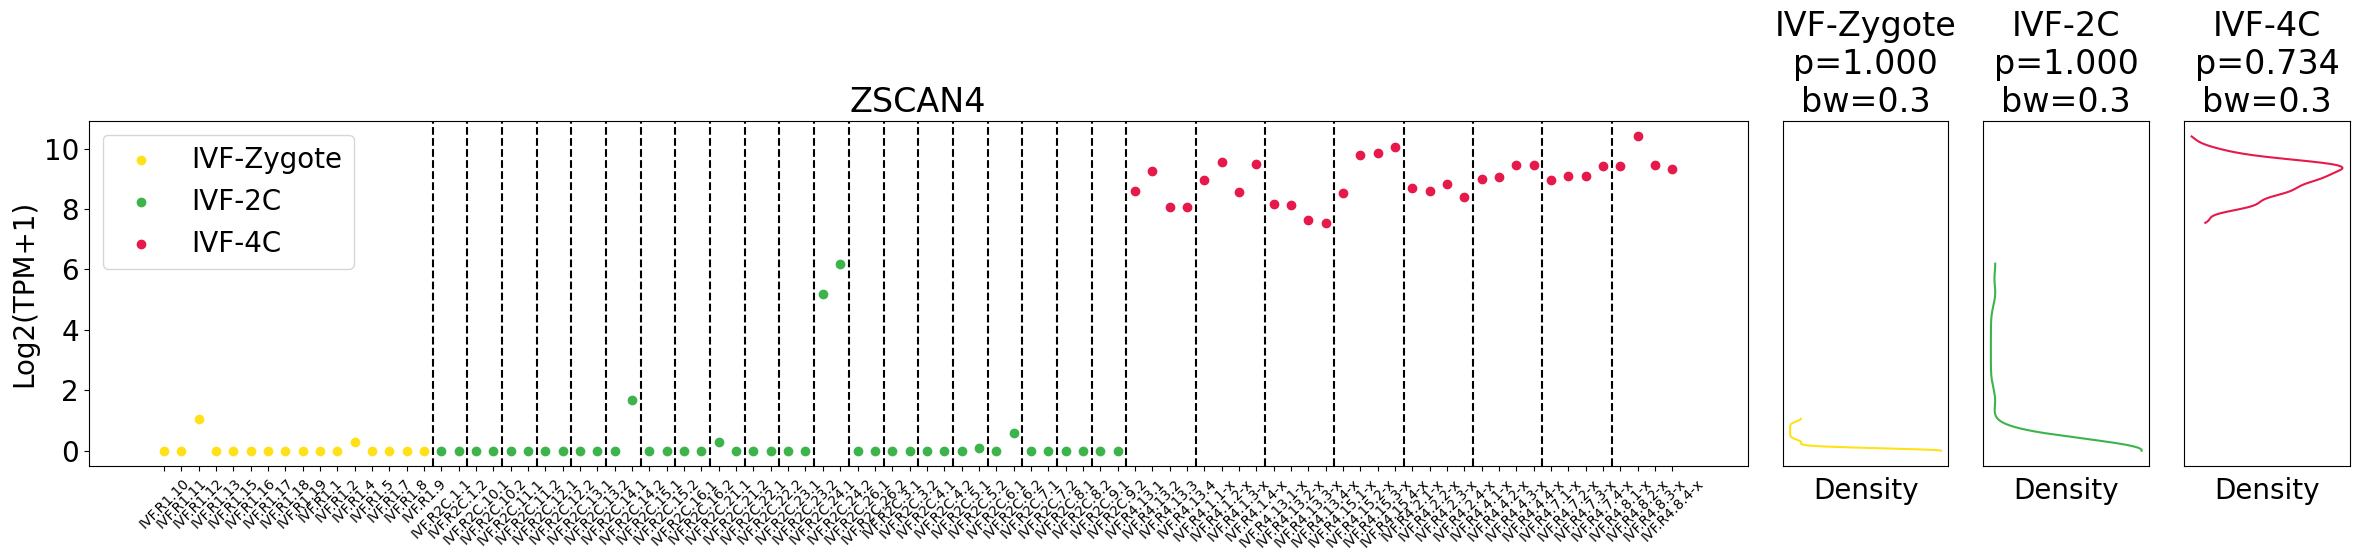

In [4]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import diptest
from scipy.stats import gaussian_kde
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置全局字体大小
plt.rcParams.update({'font.size': 20})

# 读取表达矩阵文件
with open('IVF_full_log2TPM_genename.txt', 'r') as file:
    lines = file.readlines()

# 获取细胞名
cell_names = lines[0].strip().split('\t')[1:]

# 存储基因表达数据
gene_data = {}
for line in lines[1:]:
    parts = line.strip().split('\t')
    gene_id = parts[0]
    expression_data = list(map(float, parts[1:]))
    gene_data[gene_id] = expression_data

# 选择目标基因
gene_id = "ZSCAN4"
expression_data = gene_data[gene_id]

# 提取各阶段索引和数据
mii_indices = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R1')]
c2_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R2C')]
c4_indices  = [i for i, name in enumerate(cell_names) if name.startswith('IVF.R4')]

mii_expression = np.array([expression_data[i] for i in mii_indices])
c2_expression  = np.array([expression_data[i] for i in c2_indices])
c4_expression  = np.array([expression_data[i] for i in c4_indices])

# 创建图形和子图
fig = plt.figure(figsize=(24, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[10, 1, 1, 1])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])
ax4 = plt.subplot(gs[3])

# 散点图
ax1.scatter([cell_names[i] for i in mii_indices], mii_expression, color='#ffe119', label='IVF-Zygote')
ax1.scatter([cell_names[i] for i in c2_indices], c2_expression, color='#3cb44b', label='IVF-2C')
ax1.scatter([cell_names[i] for i in c4_indices], c4_expression, color='#e6194b', label='IVF-4C')
ax1.set_title(gene_id)
ax1.set_ylabel('Log2(TPM+1)')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

# 添加虚线
for x in [15.5,17.5,19.5,21.5,23.5,25.5,27.5,29.5,31.5,33.5,35.5,
          37.5,39.5,41.5,43.5,45.5,47.5,49.5,51.5,53.5,55.5,
          59.5,63.5,67.5,71.5,75.5,79.5,83.5]:
    ax1.axvline(x=x, color='black', linestyle='--')

# 密度图函数
def plot_density(ax, data, color, label, bw=0.2):
    kde = gaussian_kde(data, bw_method=bw)
    y_vals = np.linspace(min(data), max(data), 500)
    x_vals = kde(y_vals)
    ax.plot(x_vals, y_vals, color=color)
    ax.set_ylim(ax1.get_ylim())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Density')
    ax.grid(True)
    p = diptest.diptest(data)[1]
    ax.set_title(f'{label}\np={p:.3f}\nbw={bw}')


# 绘制密度图
plot_density(ax2, mii_expression, '#ffe119', 'IVF-Zygote', bw=0.3)
plot_density(ax3, c2_expression,  '#3cb44b', 'IVF-2C',      bw=0.3)
plot_density(ax4, c4_expression,  '#e6194b', 'IVF-4C',      bw=0.3)

# 调整字体
for tick in ax1.xaxis.get_major_ticks():
    tick.label.set_fontsize(10)

plt.tight_layout()
# 保存图像为 PDF
plt.savefig('IVF_ZSCAN4_expression.svg', dpi=300, bbox_inches='tight', transparent=True)



ZSCAN4 expression
IVF-4C-iDEG1: n = 44
IVF-4C-iDEG2: n = 15


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['DejaVu Sans Display'] not found. Falling back to DejaVu Sans.


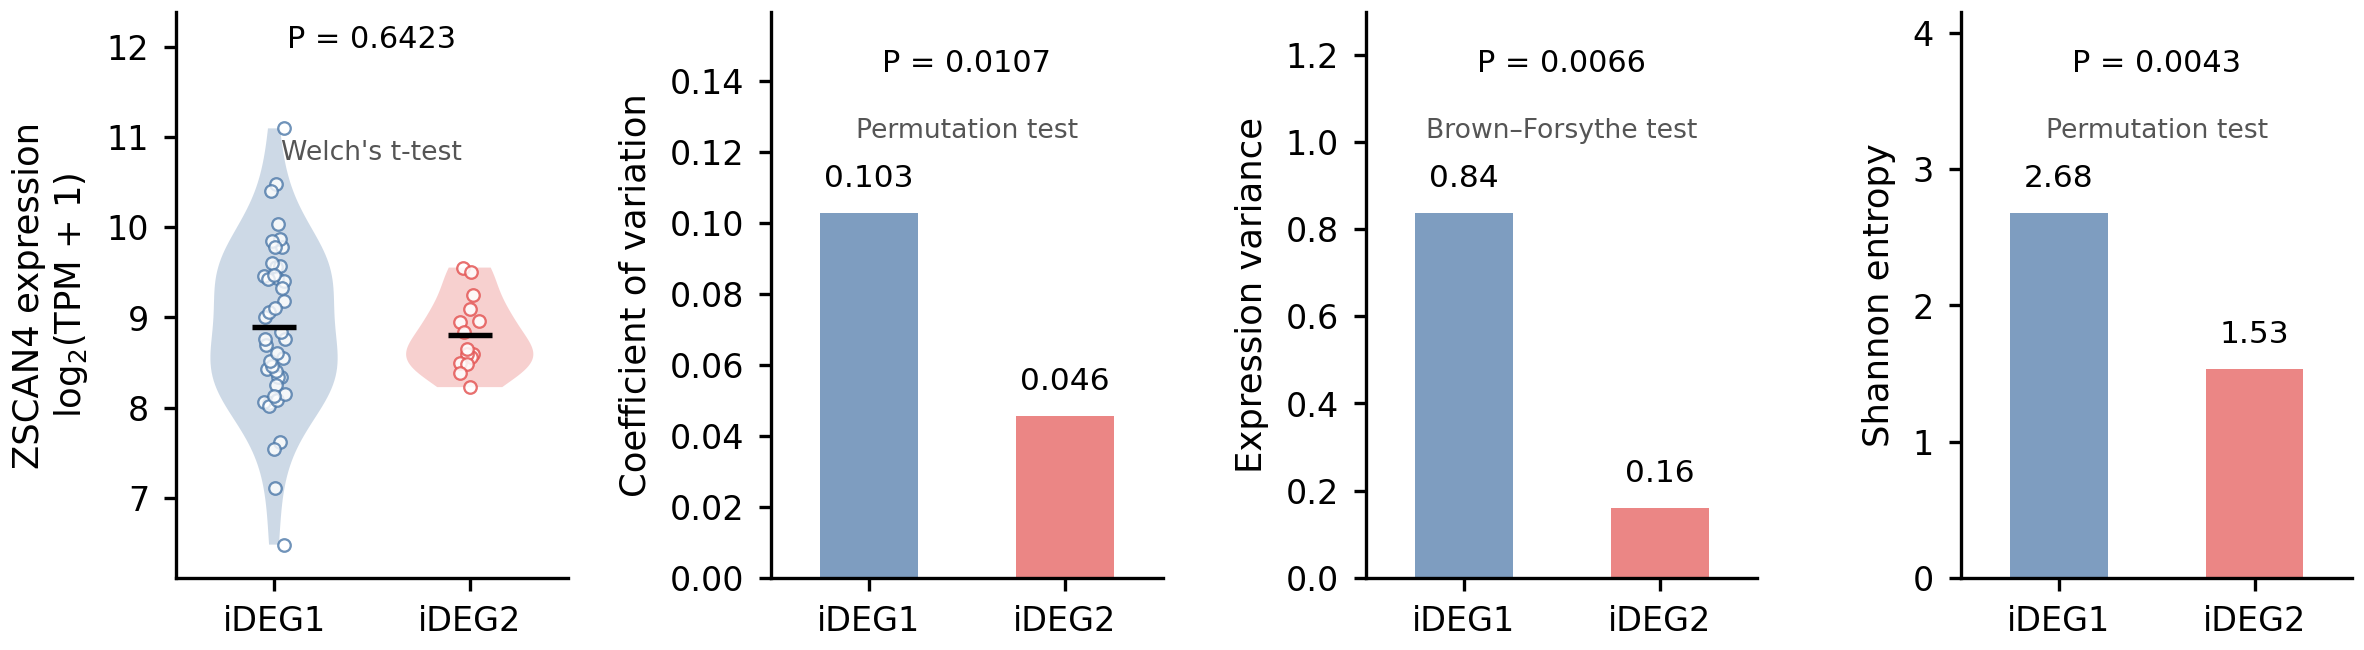


FINAL RESULTS

Mean expression:
iDEG1 = 8.889137
iDEG2 = 8.808504
Welch's t-test P = 0.642261

Coefficient of variation:
iDEG1 = 0.102952
iDEG2 = 0.045591
Permutation P = 0.0106989

Variance:
iDEG1 = 0.837501
iDEG2 = 0.161270
Brown–Forsythe P = 0.00662626

Shannon entropy:
iDEG1 = 2.679961
iDEG2 = 1.530125
Permutation P = 0.00429957

Output:
ZSCAN4_R1_R2_four_metrics.svg
ZSCAN4_R1_R2_four_metrics_statistics.txt


In [2]:
# ============================================================
# ZSCAN4 expression heterogeneity
# IVF-4C-R1 vs IVF-4C-R2
#
# Four panels in one row:
#
#   1. Mean expression       -> violin + individual cells
#   2. Coefficient variation -> bar
#   3. Variance              -> bar
#   4. Shannon entropy       -> bar
#
# No panel labels (a/b/c/d)
#
# Statistical tests:
#   Mean expression : Welch's t-test
#   CV              : permutation test
#   Variance        : Brown–Forsythe test
#   Entropy         : permutation test
#
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    ttest_ind,
    levene
)

from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ============================================================
# 0. Parameters
# ============================================================

EXPR_FILE = "IVF_4C_all_log2TPM_genename.txt"
GROUP_FILE = "IVF_4C_group.txt"

TARGET_GENE = "ENSSSCG00000003987"

GROUP1 = "IVF-4C-iDEG1"
GROUP2 = "IVF-4C-iDEG2"

N_PERM = 10000
SEED = 2026

OUT_PREFIX = "ZSCAN4_R1_R2_four_metrics"


# ============================================================
# 1. Matplotlib settings
# ============================================================

plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams["axes.linewidth"] = 0.8

plt.rcParams["xtick.major.width"] = 0.8
plt.rcParams["ytick.major.width"] = 0.8

plt.rcParams["xtick.major.size"] = 3
plt.rcParams["ytick.major.size"] = 3

plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 600

plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["savefig.pad_inches"] = 0.04


# ============================================================
# 2. Colors
# ============================================================

COLOR_R1 = "#4C78A8"
COLOR_R2 = "#E45756"

DOT_COLOR = "#333333"


# ============================================================
# 3. Read expression matrix
# ============================================================

expr = pd.read_csv(
    EXPR_FILE,
    sep="\t",
    index_col=0
)

if TARGET_GENE not in expr.index:

    raise ValueError(
        f"{TARGET_GENE} was not found in "
        f"{EXPR_FILE}"
    )


zscan4 = pd.to_numeric(
    expr.loc[TARGET_GENE],
    errors="coerce"
)


# ============================================================
# 4. Read group information
# ============================================================

group = pd.read_csv(
    GROUP_FILE,
    sep="\t",
    index_col=0
)


if group.shape[1] == 1:

    group_series = group.iloc[:, 0]

else:

    candidate_columns = []

    for col in group.columns:

        values = (
            group[col]
            .astype(str)
        )

        if values.isin(
            [GROUP1, GROUP2]
        ).any():

            candidate_columns.append(
                col
            )

    if len(candidate_columns) == 0:

        raise ValueError(
            "Could not identify group column."
        )

    group_series = group[
        candidate_columns[0]
    ]


# ============================================================
# 5. Match samples
# ============================================================

common_samples = (
    zscan4.index
    .intersection(
        group_series.index
    )
)


if len(common_samples) == 0:

    raise ValueError(
        "No common sample IDs were found."
    )


df = pd.DataFrame({

    "sample":
        common_samples,

    "expression":
        zscan4.loc[
            common_samples
        ].values,

    "group":
        group_series.loc[
            common_samples
        ].values

})


df = df[
    df["group"].isin(
        [GROUP1, GROUP2]
    )
].copy()


df["expression"] = pd.to_numeric(
    df["expression"],
    errors="coerce"
)


df = df.dropna(
    subset=["expression"]
)


# ============================================================
# 6. Extract groups
# ============================================================

r1 = df.loc[
    df["group"] == GROUP1,
    "expression"
].to_numpy()

r2 = df.loc[
    df["group"] == GROUP2,
    "expression"
].to_numpy()


print("\n==============================================")
print("ZSCAN4 expression")
print("==============================================")

print(
    f"{GROUP1}: n = {len(r1)}"
)

print(
    f"{GROUP2}: n = {len(r2)}"
)


# ============================================================
# 7. Summary functions
# ============================================================

def mean_value(x):

    return np.mean(x)


def variance_value(x):

    return np.var(
        x,
        ddof=1
    )


def sd_value(x):

    return np.std(
        x,
        ddof=1
    )


def cv_value(x):

    mean = np.mean(x)

    if mean == 0:

        return np.nan

    return (
        np.std(
            x,
            ddof=1
        )
        /
        mean
    )


# ============================================================
# 8. Common bins for Shannon entropy
# ============================================================

combined = np.concatenate(
    [r1, r2]
)


q25, q75 = np.percentile(
    combined,
    [25, 75]
)

iqr = q75 - q25


if iqr > 0:

    bin_width = (
        2 *
        iqr /
        (
            len(combined) ** (1 / 3)
        )
    )

else:

    bin_width = (
        np.ptp(combined) /
        10
    )


if bin_width <= 0:

    bin_width = 1.0


n_bins = int(
    np.ceil(
        (
            np.max(combined)
            -
            np.min(combined)
        )
        /
        bin_width
    )
)


n_bins = max(
    5,
    min(
        n_bins,
        30
    )
)


bins = np.linspace(
    np.min(combined),
    np.max(combined),
    n_bins + 1
)


# ============================================================
# 9. Shannon entropy
# ============================================================

def shannon_entropy(
    x,
    bins
):

    counts, _ = np.histogram(
        x,
        bins=bins
    )

    counts = counts[
        counts > 0
    ]

    probabilities = (
        counts /
        counts.sum()
    )

    return -np.sum(
        probabilities *
        np.log2(probabilities)
    )


# ============================================================
# 10. Observed metrics
# ============================================================

mean_r1 = mean_value(r1)
mean_r2 = mean_value(r2)

cv_r1 = cv_value(r1)
cv_r2 = cv_value(r2)

var_r1 = variance_value(r1)
var_r2 = variance_value(r2)

entropy_r1 = shannon_entropy(
    r1,
    bins
)

entropy_r2 = shannon_entropy(
    r2,
    bins
)


# ============================================================
# 11. Statistical tests
# ============================================================

# ------------------------------------------------------------
# Mean
# ------------------------------------------------------------

mean_stat, mean_p = ttest_ind(
    r1,
    r2,
    equal_var=False
)


# ------------------------------------------------------------
# Variance
# Brown–Forsythe test
# ------------------------------------------------------------

bf_stat, bf_p = levene(
    r1,
    r2,
    center="median"
)


# ============================================================
# 12. Permutation test
# ============================================================

def permutation_test(
    x,
    y,
    statistic_function,
    n_perm=10000,
    seed=2026
):

    rng = np.random.default_rng(
        seed
    )

    observed = (
        statistic_function(x)
        -
        statistic_function(y)
    )

    pooled = np.concatenate(
        [x, y]
    )

    nx = len(x)

    count = 0

    for _ in range(
        n_perm
    ):

        shuffled = rng.permutation(
            pooled
        )

        x_perm = shuffled[
            :nx
        ]

        y_perm = shuffled[
            nx:
        ]

        stat_perm = (
            statistic_function(
                x_perm
            )
            -
            statistic_function(
                y_perm
            )
        )

        if abs(stat_perm) >= abs(observed):

            count += 1

    p_value = (
        count + 1
    ) / (
        n_perm + 1
    )

    return (
        observed,
        p_value
    )


# ============================================================
# 13. CV permutation test
# ============================================================

cv_diff, cv_p = permutation_test(
    r1,
    r2,
    cv_value,
    n_perm=N_PERM,
    seed=SEED
)


# ============================================================
# 14. Entropy permutation test
# ============================================================

def entropy_function(x):

    return shannon_entropy(
        x,
        bins
    )


entropy_diff, entropy_p = permutation_test(
    r1,
    r2,
    entropy_function,
    n_perm=N_PERM,
    seed=SEED + 1
)


# ============================================================
# 15. Save statistics
# ============================================================

stats_file = (
    f"{OUT_PREFIX}_statistics.txt"
)


with open(
    stats_file,
    "w"
) as f:

    f.write(
        "ZSCAN4 expression heterogeneity\n"
    )

    f.write(
        "IVF-4C-iDEG1 vs IVF-4C-iDEG2\n"
    )

    f.write(
        "========================================\n\n"
    )

    f.write(
        f"Target gene: {TARGET_GENE}\n"
    )

    f.write(
        f"{GROUP1}: n = {len(r1)}\n"
    )

    f.write(
        f"{GROUP2}: n = {len(r2)}\n\n"
    )

    f.write(
        "Mean expression\n"
    )

    f.write(
        f"iDEG1 = {mean_r1}\n"
    )

    f.write(
        f"iDEG2 = {mean_r2}\n"
    )

    f.write(
        f"Welch's t-test P = {mean_p}\n\n"
    )


    f.write(
        "Coefficient of variation\n"
    )

    f.write(
        f"iDEG1 = {cv_r1}\n"
    )

    f.write(
        f"iDEG2 = {cv_r2}\n"
    )

    f.write(
        f"Permutation P = {cv_p}\n\n"
    )


    f.write(
        "Variance\n"
    )

    f.write(
        f"iDEG1 = {var_r1}\n"
    )

    f.write(
        f"iDEG2 = {var_r2}\n"
    )

    f.write(
        f"Brown-Forsythe P = {bf_p}\n\n"
    )


    f.write(
        "Shannon entropy\n"
    )

    f.write(
        f"iDEG1 = {entropy_r1}\n"
    )

    f.write(
        f"iDEG2 = {entropy_r2}\n"
    )

    f.write(
        f"Permutation P = {entropy_p}\n\n"
    )

    f.write(
        f"Number of entropy bins = "
        f"{n_bins}\n"
    )

    f.write(
        f"Permutation iterations = "
        f"{N_PERM}\n"
    )


# ============================================================
# 16. Helper functions for plotting
# ============================================================

def format_p(p):

    if p < 0.0001:

        return "P < 0.0001"

    return f"P = {p:.4f}"


def add_pvalue(
    ax,
    p,
    test_name,
    y
):

    ax.text(
        1.5,
        y,
        format_p(p),
        ha="center",
        va="bottom",
        fontsize=7.3
    )

    ax.text(
        1.5,
        y - (
            0.08 * y
            if y != 0
            else 0.08
        ),
        test_name,
        ha="center",
        va="top",
        fontsize=6.4,
        color="#555555"
    )


# ============================================================
# 17. Figure
# ============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(7.8, 2.55)
)


# ============================================================
# PANEL 1
# Mean expression
# ============================================================

ax = axes[0]


data = [
    r1,
    r2
]


# ------------------------------------------------------------
# Violin
# ------------------------------------------------------------

violin = ax.violinplot(
    data,
    positions=[1, 2],
    widths=0.65,
    showmeans=False,
    showmedians=False,
    showextrema=False
)


for i, body in enumerate(
    violin["bodies"]
):

    if i == 0:

        body.set_facecolor(
            COLOR_R1
        )

    else:

        body.set_facecolor(
            COLOR_R2
        )

    body.set_edgecolor(
        "none"
    )

    body.set_alpha(
        0.28
    )


# ------------------------------------------------------------
# Individual cells
# ------------------------------------------------------------

rng1 = np.random.default_rng(
    100
)

rng2 = np.random.default_rng(
    200
)


x1 = (
    1 +
    rng1.uniform(
        -0.055,
        0.055,
        len(r1)
    )
)


x2 = (
    2 +
    rng2.uniform(
        -0.055,
        0.055,
        len(r2)
    )
)


ax.scatter(
    x1,
    r1,
    s=9,
    facecolor="white",
    edgecolor=COLOR_R1,
    linewidth=0.55,
    alpha=0.80,
    zorder=3
)


ax.scatter(
    x2,
    r2,
    s=9,
    facecolor="white",
    edgecolor=COLOR_R2,
    linewidth=0.55,
    alpha=0.85,
    zorder=3
)

# ------------------------------------------------------------
# Mean marker
# ------------------------------------------------------------

ax.scatter(
    [1, 2],
    [mean_r1, mean_r2],
    marker="_",
    s=110,
    color="black",
    linewidth=1.3,
    zorder=7
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xticks(
    [1, 2]
)

ax.set_xticklabels(
    ["iDEG1", "iDEG2"]
)

ax.set_ylabel(
    "ZSCAN4 expression\nlog$_2$(TPM + 1)"
)

ax.set_xlim(
    0.5,
    2.5
)


ymin = np.min(
    combined
)

ymax = np.max(
    combined
)

yrange = ymax - ymin

if yrange == 0:

    yrange = 1


ax.set_ylim(
    ymin - yrange * 0.08,
    ymax + yrange * 0.28
)


# P value

add_pvalue(
    ax,
    mean_p,
    "Welch's t-test",
    ymax + yrange * 0.18
)


# ============================================================
# PANEL 2
# CV
# ============================================================

ax = axes[1]


values = [
    cv_r1,
    cv_r2
]


ax.bar(
    [1, 2],
    values,
    width=0.50,
    color=[
        COLOR_R1,
        COLOR_R2
    ],
    alpha=0.72,
    edgecolor="none"
)


# Values

for x, value in zip(
    [1, 2],
    values
):

    ax.text(
        x,
        value + max(values) * 0.055,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=7.5
    )


ax.set_xticks(
    [1, 2]
)

ax.set_xticklabels(
    ["iDEG1", "iDEG2"]
)

ax.set_ylabel(
    "Coefficient of variation"
)

ax.set_xlim(
    0.5,
    2.5
)

ax.set_ylim(
    0,
    max(values) * 1.55
)


add_pvalue(
    ax,
    cv_p,
    "Permutation test",
    max(values) * 1.37
)


# ============================================================
# PANEL 3
# Variance
# ============================================================

ax = axes[2]


values = [
    var_r1,
    var_r2
]


ax.bar(
    [1, 2],
    values,
    width=0.50,
    color=[
        COLOR_R1,
        COLOR_R2
    ],
    alpha=0.72,
    edgecolor="none"
)


for x, value in zip(
    [1, 2],
    values
):

    ax.text(
        x,
        value + max(values) * 0.055,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=7.5
    )


ax.set_xticks(
    [1, 2]
)

ax.set_xticklabels(
    ["iDEG1", "iDEG2"]
)

ax.set_ylabel(
    "Expression variance"
)

ax.set_xlim(
    0.5,
    2.5
)

ax.set_ylim(
    0,
    max(values) * 1.55
)


add_pvalue(
    ax,
    bf_p,
    "Brown–Forsythe test",
    max(values) * 1.37
)


# ============================================================
# PANEL 4
# Shannon entropy
# ============================================================

ax = axes[3]


values = [
    entropy_r1,
    entropy_r2
]


ax.bar(
    [1, 2],
    values,
    width=0.50,
    color=[
        COLOR_R1,
        COLOR_R2
    ],
    alpha=0.72,
    edgecolor="none"
)


for x, value in zip(
    [1, 2],
    values
):

    ax.text(
        x,
        value + max(values) * 0.055,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=7.5
    )


ax.set_xticks(
    [1, 2]
)

ax.set_xticklabels(
    ["iDEG1", "iDEG2"]
)

ax.set_ylabel(
    "Shannon entropy"
)

ax.set_xlim(
    0.5,
    2.5
)

ax.set_ylim(
    0,
    max(values) * 1.55
)


add_pvalue(
    ax,
    entropy_p,
    "Permutation test",
    max(values) * 1.37
)


# ============================================================
# 18. Remove unnecessary spines
# ============================================================

for ax in axes:

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


# ============================================================
# 19. Layout
# ============================================================

plt.subplots_adjust(
    left=0.065,
    right=0.995,
    bottom=0.23,
    top=0.97,
    wspace=0.52
)


# ============================================================
# 20. Save
# ============================================================

fig.savefig(
    f"{OUT_PREFIX}.svg", dpi=300, bbox_inches='tight'
)

plt.show()


# ============================================================
# 21. Print final results
# ============================================================

print("\n==============================================")
print("FINAL RESULTS")
print("==============================================")

print(
    "\nMean expression:"
)

print(
    f"iDEG1 = {mean_r1:.6f}"
)

print(
    f"iDEG2 = {mean_r2:.6f}"
)

print(
    f"Welch's t-test P = {mean_p:.6g}"
)


print(
    "\nCoefficient of variation:"
)

print(
    f"iDEG1 = {cv_r1:.6f}"
)

print(
    f"iDEG2 = {cv_r2:.6f}"
)

print(
    f"Permutation P = {cv_p:.6g}"
)


print(
    "\nVariance:"
)

print(
    f"iDEG1 = {var_r1:.6f}"
)

print(
    f"iDEG2 = {var_r2:.6f}"
)

print(
    f"Brown–Forsythe P = {bf_p:.6g}"
)


print(
    "\nShannon entropy:"
)

print(
    f"iDEG1 = {entropy_r1:.6f}"
)

print(
    f"iDEG2 = {entropy_r2:.6f}"
)

print(
    f"Permutation P = {entropy_p:.6g}"
)


print(
    "\nOutput:"
)

print(
    f"{OUT_PREFIX}.svg"
)

print(
    stats_file
)